# Anguish – Lava (Harakim)

Anguish (Lava) puts a 30 s marker on the target. The caster's next **Blast** against that target
consumes the marker and multiplies its damage by ×1.50 or more. The marker does nothing else: it
deals no damage and only Blast reads it.

**Rebalanced.** The multiplier used to be `clamp(150 + m/2, 150, 200)`, which reached ×2 at
modified skill 100, below the raise cap. Everything past that was wasted. It now follows the
shared mod-300 knee (`skill_knee_300(m, 150, 200)`): ×1.50 at skill 0, ×2.00 at modified skill
300, then half the slope with no hard limit. The "before" curves below show the old formula.

| | |
|---|---|
| Class | Harakim |
| Target | Single hostile |
| Cost | 30 mana (not divided by 3 for Harakim), spent before the roll |
| Cooldown | none: Anguish adds no exhaust (it is refused while exhausted) |
| Landing roll | `chance_base(skill, 10, effective_resist(Resist))` |
| Duration | 30 s, or until the next Blast on the target |
| Effect | `compute_blast_damage`: `dam = 2p' · skill_knee_300(m, 150, 200) / 100`, with $m$ the caster's **modified** Anguish (Lava) skill when the marker was placed (stored in the marker's `power`, not reduced by Immunity) |
| Source | `server/src/driver/skill/harakim.rs::skill_anguish_lava`, `anguish_preflight`; `driver/skill/blast.rs::compute_blast_damage`; knee in `driver/skill/common.rs::skill_knee_300` |

---

# Formula

With $m$ the modified Anguish (Lava) skill stored in the marker and $p'$ the Blast power after
Immunity and race:

$$
k = \begin{cases}
150 + \left\lfloor \dfrac{50\,m}{300} \right\rfloor & m \le 300 \\[2ex]
200 + \left\lfloor \dfrac{50\,(m - 300)}{600} \right\rfloor & m > 300
\end{cases}
\qquad
\text{dam} = \left\lfloor \frac{2p' \cdot k}{100} \right\rfloor
\qquad
\text{Blast cost} = \left\lfloor \frac{\lfloor \text{dam}/8 \rfloor + 5}{3} \right\rfloor
$$

The multiplier is applied before armor and before the splash, so the 75% splash is boosted too.
Blast's mana cost is computed from the multiplied damage, so a consuming Blast costs more.

$$
P(\text{marker lands}) = \frac{\operatorname{clamp}\!\left(\lfloor 10m/R_\text{eff}\rfloor,\ 0,\ 18\right) + 1}{20}
\quad (0 \text{ if } R_\text{eff} > \lfloor 3m/2 \rfloor)
$$

| Quantity | Breakpoint |
|---|---|
| Floor | ×1.50 for $m \le 5$ |
| At the raise cap ($m$ 105) | ×1.67 (before: ×2.00) |
| Endgame ($m$ 275 / 300) | ×1.95 / ×2.00 (before: ×2.00 from $m \ge 100$) |
| Past the knee ($m$ 350 / 450 / 600) | ×2.04 / ×2.12 / ×2.25 |
| Hard limit | none |
| Combo cost at 105 | 30 (Anguish) + 16 (boosted Blast) = 46 mana, against 10 for a plain Blast (before: 49) |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
ANGUISH_COST = 30
MARKER_S = 30
EXHAUST_S = 6

# Model

In [2]:
def multiplier_pct(m):
    return mm.knee_300(m, 150, 200)


def blast_dam(pp, m=None, mult=multiplier_pct):
    dam = np.asarray(pp) * 2
    if m is None:
        return dam
    return dam * mult(m) // 100


def blast_cost(dam):
    return mm.idiv(np.asarray(dam) // 8 + 5, 3)


def p_marker(m, resist):
    return mm.p_chance_base(m, 10, resist)


def cycle(p, resist, armor=0, immun=0, splash_targets=0, mult=multiplier_pct):
    """(expected HP, expected mana) of one 6 s cycle of Anguish + Blast vs a plain Blast."""
    pp = mm.spell_power(p, immun, "Harakim")
    q = p_marker(p, resist)
    plain, boosted = blast_dam(pp), blast_dam(pp, p, mult)

    def hp(dam):
        splash = dam // 2 + dam // 4
        return mm.hurt_hp(dam, armor, 1) + splash_targets * mm.hurt_hp(splash, armor, 1)

    combo_hp = q * hp(boosted) + (1 - q) * hp(plain)
    combo_mana = ANGUISH_COST + q * blast_cost(boosted) + (1 - q) * blast_cost(plain)
    return (combo_hp, combo_mana), (hp(plain), blast_cost(plain))


# Before the rebalance: +1% per 2 skill points, capped at ×2 from skill 100.
def old_multiplier_pct(m):
    return mm.clamp(150 + mm.idiv(m, 2), 150, 200)

# Validation

- `compute_blast_damage_consumes_anguish_lava_for_bonus_damage`: Blast skill 50 (base 100) with
  a marker of power 25 → (50, 154), and the marker's `active` drops to 0.
- `compute_blast_damage_doubles_at_anguish_lava_300_then_half_slope`: Blast skill 50, marker
  power 300 → (50, 200), marker power 450 → (50, 212).
- `anguish_preflight_rejects_self_target_without_cost` and
  `anguish_preflight_is_refused_while_exhausted`: no mana is spent in either case.

In [3]:
assert blast_dam(50) == 100
assert multiplier_pct(25) == 154 and blast_dam(50, 25) == 154
assert multiplier_pct(300) == 200 and blast_dam(50, 300) == 200
assert multiplier_pct(450) == 212 and blast_dam(50, 450) == 212
assert multiplier_pct(0) == 150 and multiplier_pct(5) == 150 and multiplier_pct(6) == 151
assert [int(multiplier_pct(m)) for m in (105, 275, 350, 600)] == [167, 195, 204, 225]
assert blast_cost(blast_dam(105)) == 10 and blast_cost(blast_dam(105, 105)) == 16
assert old_multiplier_pct(25) == 162 and old_multiplier_pct(100) == 200 and old_multiplier_pct(500) == 200
assert blast_cost(blast_dam(105, 105, old_multiplier_pct)) == 19
print("Anguish-Lava model OK")

Anguish-Lava model OK


# Plots

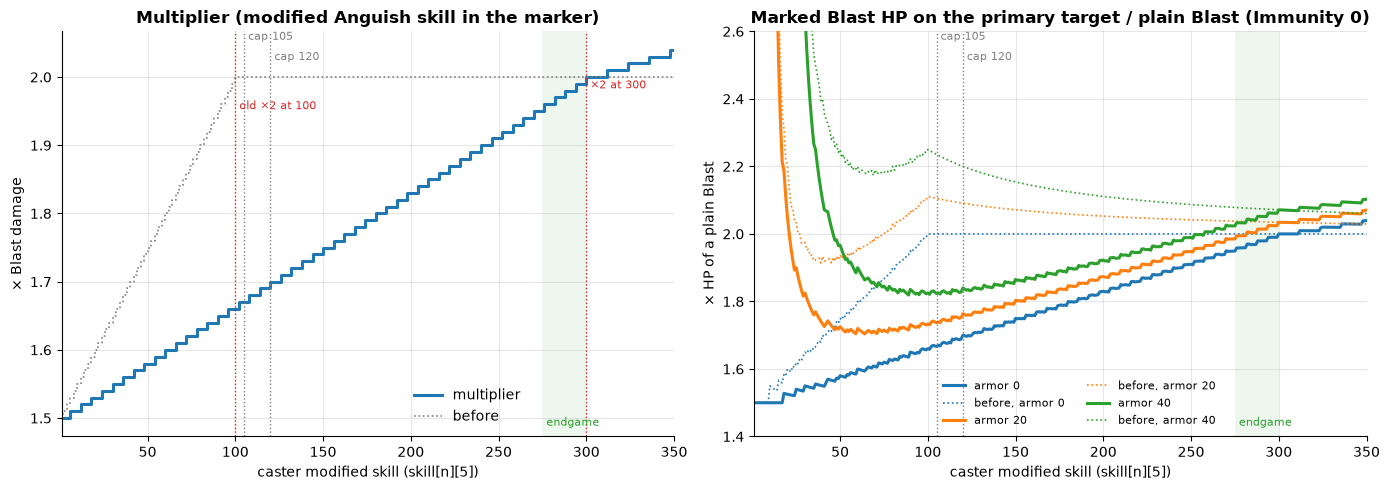

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.step(P, multiplier_pct(P) / 100, where="post", lw=2.2, label="multiplier")
ax.step(P, old_multiplier_pct(P) / 100, where="post", color="grey", lw=1.2, ls=":", label="before")
mm.skill_axis(ax, "× Blast damage", "Multiplier (modified Anguish skill in the marker)")
mm.mark_caps(ax, extra=[(300, "×2 at 300"), (100, "old ×2 at 100")])
ax.legend(loc="lower right", bbox_to_anchor=(0.77, 0))

ax = axes[1]
pp = mm.spell_power(P, 0, "Harakim")
for armor in (0, 20, 40):
    plain = np.asarray(mm.hurt_hp(blast_dam(pp), armor, 1), dtype=float)
    plain[plain == 0] = np.nan  # armor swallows the whole plain Blast at very low skill
    line, = ax.plot(P, mm.hurt_hp(blast_dam(pp, P), armor, 1) / plain, lw=2.2, label=f"armor {armor}")
    ax.plot(P, mm.hurt_hp(blast_dam(pp, P, old_multiplier_pct), armor, 1) / plain,
            color=line.get_color(), lw=1.2, ls=":", label=f"before, armor {armor}")
mm.skill_axis(ax, "× HP of a plain Blast", "Marked Blast HP on the primary target / plain Blast (Immunity 0)")
ax.set_ylim(1.4, 2.6)
mm.mark_caps(ax)
ax.legend(fontsize=8, loc="lower right", bbox_to_anchor=(0.77, 0), ncol=2)
plt.tight_layout()

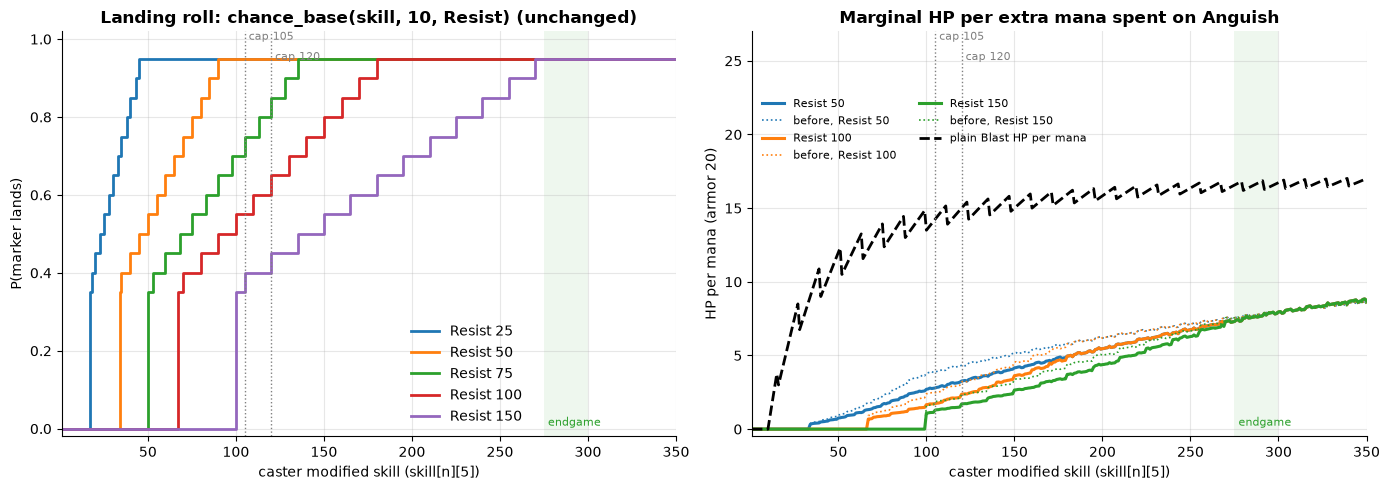

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for r in mm.RESIST_SWEEP:
    ax.step(P, p_marker(P, r), where="post", label=f"Resist {r}")
mm.skill_axis(ax, "P(marker lands)", "Landing roll: chance_base(skill, 10, Resist) (unchanged)")
ax.set_ylim(-0.02, 1.02)
mm.mark_caps(ax)
ax.legend(loc="lower right", bbox_to_anchor=(0.77, 0))

ax = axes[1]
for r in (50, 100, 150):
    (chp, cmana), (php, pmana) = cycle(P, r, armor=20)
    line, = ax.plot(P, (chp - php) / (cmana - pmana), lw=2.2, label=f"Resist {r}")
    (chp, cmana), (php, pmana) = cycle(P, r, armor=20, mult=old_multiplier_pct)
    ax.plot(P, (chp - php) / (cmana - pmana), color=line.get_color(), lw=1.2, ls=":",
            label=f"before, Resist {r}")
(_, _), (php, pmana) = cycle(P, 50, armor=20)
ax.plot(P, php / pmana, color="black", ls="--", label="plain Blast HP per mana")
mm.skill_axis(ax, "HP per mana (armor 20)", "Marginal HP per extra mana spent on Anguish")
mm.mark_caps(ax)
ax.set_ylim(-0.5, 27)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.86), ncol=2)
plt.tight_layout()

# Observations

The plots assume the caster has the same modified skill in Anguish (Lava) and Blast.

- The Harakim talent tree's "Elemental Anguish" node teaches only
  Anguish (Earth). I found no other grant of `SK_ANGUISH_LAVA` in `core/` or `server/`, so the skill
  is reachable only by editing the character directly.
- Only `compute_blast_damage` (plain Blast and the Seyan'Du
  Free Blast rune) consumes the marker. The Lava Blast talent replaces Blast, so a Harakim with Lava
  Blast has nothing that reads the marker. The two are designed as a pair (lava element) but are
  mutually exclusive.
- At modified skill 275–300 the multiplier is
  ×1.95–×2.00, the same ×2.00 as before at 300. At the raise cap of 105 it is ×1.67 instead of
  ×2.00, and the new curve is at or below the old one everywhere below 300. The skill now pays off
  across the whole range instead of stopping at 100.
- Skill 350 gives ×2.04 (+4 points over 300), 450 gives ×2.12 and
  600 gives ×2.25. There is no hard limit, but growth is slow.
- The target's Immunity does not reduce the multiplier;
  it only reduces the Blast power $p'$ and the landing roll.
- At skill 105 a marked Blast does ×1.82 the HP
  of a plain one against armor 40 (before: ×2.24) and ×1.74 against armor 20. At 300 it is ×2.07
  against armor 40. The splash is boosted as well.
- A plain Blast at 105 deals 142.5 HP against armor 20 for 10 mana
  (14.25 HP per mana). Anguish + Blast costs 30 + 16 = 46 mana (before: 49), because Blast's cost
  is computed from the multiplied damage. Every extra mana buys 2.8 HP against Resist 50 and
  1.7 HP against Resist 100 (before: 3.9 and 2.5). At skill 275 it buys 7.3 HP against 16.6 HP
  per mana for a plain Blast, so the combo is never mana-efficient.
- Anguish adds no exhaust, so it fits in
  front of every Blast. Against Resist 50 at skill 105 a 6 s cycle deals 242 HP instead of 142.5
  (before: 292).
- "Empowers your next Blast" omits that the
  empowered Blast costs extra mana.
- Let Lava Blast consume the marker (and amplify the burn), compute
  Blast's cost from the unmultiplied damage, and grant Anguish (Lava) somewhere in the tree. The
  lower mid-game multiplier makes the cost issue more visible.